# Transmission Line Fault Classification using 1D CNN

### AI/ML Mini Project

**Name:** Bhaavya Jain  
**Roll Number:** 1025150361

## Problem Definition

Transmission lines are an important part of electrical power systems and may experience different types of electrical faults. Rapid and accurate identification of these faults can help improve the reliability and protection of the power system.

The objective of this project is to develop a 1D Convolutional Neural Network (CNN) model to classify transmission line operating conditions using three-phase current and voltage measurements.

The input parameters are Ia, Ib, Ic, Va, Vb and Vc. The model classifies the measurements into six classes: No Fault, LG, LL, LLG, LLL and LLLG. Therefore, this is a multi-class classification problem.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("classData.csv")

## Dataset Description

The dataset contains measurements obtained from a simulated electrical power system under normal and different fault conditions.

The input features consist of three-phase current measurements (Ia, Ib, Ic) and three-phase voltage measurements (Va, Vb, Vc). The original output is represented using four binary columns G, C, B and A, which indicate ground and phase involvement in a fault.

These output combinations were converted into a single target variable called Fault_Type containing six classes: No Fault, LG, LL, LLG, LLL and LLLG.

Note: The fault-class mapping was determined from the label combinations present in the classification dataset, with the LL class represented by the combination [0, 1, 1, 0] in the downloaded CSV.

The dataset contains 7,861 observations.

## Dataset Understanding

In [2]:
df.head()

,G,C,B,A,Ia,Ib,Ic,Va,Vb,Vc
0,1,0,0,1,-151.291812,-9.677452,85.800162,0.400750,-0.132935,-0.267815
1,1,0,0,1,-336.186183,-76.283262,18.328897,0.312732,-0.123633,-0.189099
2,1,0,0,1,-502.891583,-174.648023,-80.924663,0.265728,-0.114301,-0.151428
3,1,0,0,1,-593.941905,-217.703359,-124.891924,0.235511,-0.104940,-0.130570
4,1,0,0,1,-643.663617,-224.159427,-132.282815,0.209537,-0.095554,-0.113983


In [3]:
df.shape

(7861, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7861 entries, 0 to 7860
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   G       7861 non-null   int64  
 1   C       7861 non-null   int64  
 2   B       7861 non-null   int64  
 3   A       7861 non-null   int64  
 4   Ia      7861 non-null   float64
 5   Ib      7861 non-null   float64
 6   Ic      7861 non-null   float64
 7   Va      7861 non-null   float64
 8   Vb      7861 non-null   float64
 9   Vc      7861 non-null   float64
dtypes: float64(6), int64(4)
memory usage: 614.3 KB


In [5]:
df[["G", "C", "B", "A"]].drop_duplicates()

,G,C,B,A
0,1,0,0,1
1129,1,0,1,1
2263,0,1,1,0
3267,0,1,1,1
4363,1,1,1,1
5496,0,0,0,0


In [6]:
df.groupby(["G", "C", "B", "A"]).size()

G  C  B  A
0  0  0  0    2365
   1  1  0    1004
         1    1096
1  0  0  1    1129
      1  1    1134
   1  1  1    1133
dtype: int64

In [7]:
print(df.columns.tolist())

['G', 'C', 'B', 'A', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']


In [9]:
def get_fault_type(row):
    code = (row["G"], row["C"], row["B"], row["A"])

    fault_map = {
        (0, 0, 0, 0): "No Fault",
        (1, 0, 0, 1): "LG",
        (0, 1, 1, 0): "LL",
        (1, 0, 1, 1): "LLG",
        (0, 1, 1, 1): "LLL",
        (1, 1, 1, 1): "LLLG"
    }

    return fault_map[code]

df["Fault_Type"] = df.apply(get_fault_type, axis=1)

In [10]:
df["Fault_Type"].value_counts()

,count
Fault_Type,
No Fault,2365
LLG,1134
LLLG,1133
LG,1129
LLL,1096
LL,1004


## Data Preprocessing

In [11]:
df.isnull().sum()

,0
G,0
C,0
B,0
A,0
Ia,0
Ib,0
Ic,0
Va,0
Vb,0
Vc,0


In [12]:
df.duplicated().sum()

np.int64(0)

### Preprocessing Summary

The dataset contains 7,861 observations and no missing values or duplicate rows. Therefore, no observations were removed during data cleaning. The six voltage and current measurements are numerical features suitable for model development. The four original binary output columns were converted into a single target variable, Fault_Type, representing six operating conditions.

## Exploratory Data Analysis

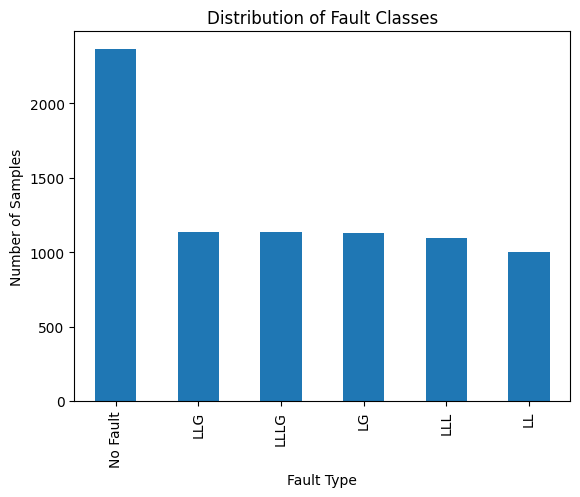

In [13]:
df["Fault_Type"].value_counts().plot(kind="bar")

plt.xlabel("Fault Type")
plt.ylabel("Number of Samples")
plt.title("Distribution of Fault Classes")
plt.show()

**Observation:** The No Fault class contains more samples than the individual fault classes, while the five fault classes have relatively similar numbers of observations. Therefore, the dataset shows some class imbalance, but all six classes contain a substantial number of samples.

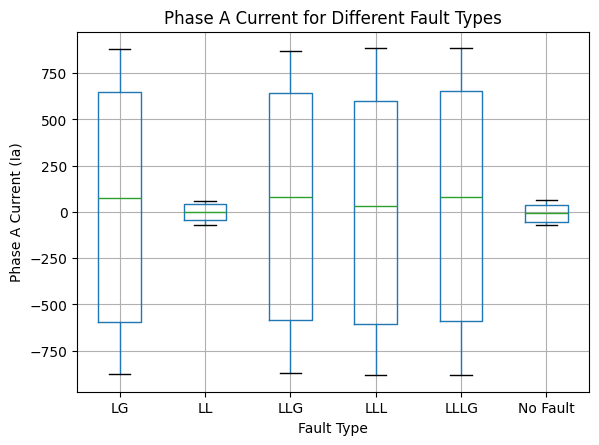

In [14]:
df.boxplot(column="Ia", by="Fault_Type")

plt.xlabel("Fault Type")
plt.ylabel("Phase A Current (Ia)")
plt.title("Phase A Current for Different Fault Types")
plt.suptitle("")
plt.show()

**Observation:** The distribution of Phase A current varies across different fault types. Several fault conditions show a much wider current range than the No Fault condition, indicating that current measurements contain useful information for distinguishing different transmission line faults.

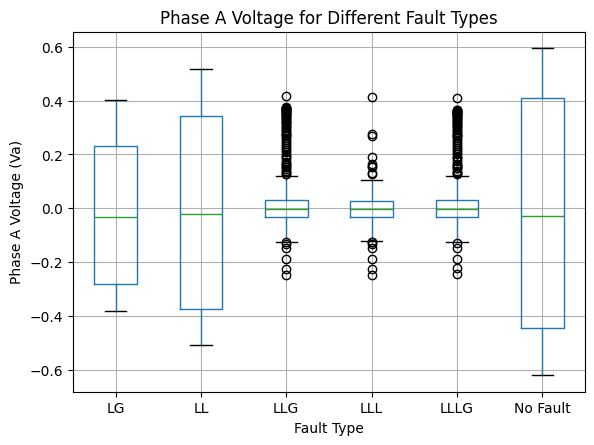

In [15]:
df.boxplot(column="Va", by="Fault_Type")

plt.xlabel("Fault Type")
plt.ylabel("Phase A Voltage (Va)")
plt.title("Phase A Voltage for Different Fault Types")
plt.suptitle("")
plt.show()

**Observation:** The distribution of Phase A voltage varies across different operating conditions. Some fault types show noticeably different voltage ranges compared with the No Fault condition, indicating that voltage measurements can provide useful information for fault classification.

## Feature Selection

The input features selected for the model are the three-phase current measurements (Ia, Ib, Ic) and three-phase voltage measurements (Va, Vb, Vc). These measurements represent the electrical behaviour of the transmission line and are used to identify different fault conditions.

The target variable is Fault_Type, which contains six classes: No Fault, LG, LL, LLG, LLL and LLLG.

In [16]:
X = df[["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]]
y = df["Fault_Type"]

print(X.shape)
print(y.shape)

(7861, 6)
(7861,)


In [17]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print(label_encoder.classes_)
print(y_encoded[:10])

['LG' 'LL' 'LLG' 'LLL' 'LLLG' 'No Fault']
[0 0 0 0 0 0 0 0 0 0]


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (6288, 6)
Testing: (1573, 6)


In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train_scaled.shape)
print(X_test_scaled.shape)

(6288, 6)
(1573, 6)


In [20]:
X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], 6, 1)
X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], 6, 1)

print(X_train_cnn.shape)
print(X_test_cnn.shape)

(6288, 6, 1)
(1573, 6, 1)


## Model Building

A 1D Convolutional Neural Network (CNN) is used to classify the transmission line operating condition. The model receives the six scaled voltage and current measurements as input and predicts one of the six fault classes.

The convolutional layers are used to learn patterns from the electrical measurements, while the final output layer performs multi-class classification.

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense

cnn_model = Sequential([
    Input(shape=(6, 1)),
    Conv1D(32, 2, activation="relu"),
    MaxPooling1D(2),
    Conv1D(64, 2, activation="relu"),
    Flatten(),
    Dense(32, activation="relu"),
    Dense(6, activation="softmax")
])

cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 5, 32)          │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 2, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 1, 64)          │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           198 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,534 (25.52 KB)

 Trainable params: 6,534 (25.52 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [24]:
history = cnn_model.fit(
    X_train_cnn,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.5497 - loss: 1.1803 - val_accuracy: 0.7138 - val_loss: 0.7195
Epoch 2/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7433 - loss: 0.6045 - val_accuracy: 0.7830 - val_loss: 0.4913
Epoch 3/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7775 - loss: 0.4762 - val_accuracy: 0.8156 - val_loss: 0.4235
Epoch 4/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7962 - loss: 0.4258 - val_accuracy: 0.8100 - val_loss: 0.3795
Epoch 5/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8105 - loss: 0.3919 - val_accuracy: 0.8060 - val_loss: 0.3795
Epoch 6/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8125 - loss: 0.3707 - val_accuracy: 0.8021 - val_loss: 0.3504
Epoch 7/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8185 - loss: 0.3524 - val_accuracy: 0.8458 - val_loss: 0.3344
Epoch 8/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8245 - loss: 0.3367 - val_accuracy: 0

## Model Evaluation

In [25]:
test_loss, test_accuracy = cnn_model.evaluate(X_test_cnn, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8417 - loss: 0.2665
Test Loss: 0.26651841402053833
Test Accuracy: 0.8417037725448608


In [26]:
import numpy as np

y_pred_prob = cnn_model.predict(X_test_cnn)
y_pred = np.argmax(y_pred_prob, axis=1)

print(y_pred[:10])
print(y_test[:10])

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
[5 3 4 5 0 3 0 0 1 1]
[1 4 3 5 0 4 0 0 1 3]


In [27]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

              precision    recall  f1-score   support

          LG       0.96      0.97      0.96       226
          LL       0.92      0.98      0.95       201
         LLG       1.00      0.97      0.98       227
         LLL       0.50      0.83      0.63       219
        LLLG       0.55      0.15      0.24       227
    No Fault       0.97      1.00      0.98       473

    accuracy                           0.84      1573
   macro avg       0.82      0.82      0.79      1573
weighted avg       0.84      0.84      0.82      1573



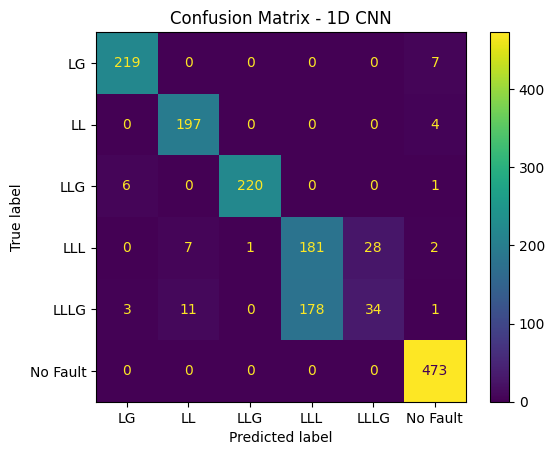

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot()
plt.title("Confusion Matrix - 1D CNN")
plt.show()

**Observation:** The 1D CNN achieved a test accuracy of approximately 84.17%. The model classified LG, LL, LLG and No Fault conditions with high accuracy. However, the confusion matrix shows that the model had difficulty distinguishing between LLL and LLLG faults, with many LLLG samples being classified as LLL. This indicates that these two fault conditions have more similar patterns in the selected voltage and current measurements compared with the other classes.

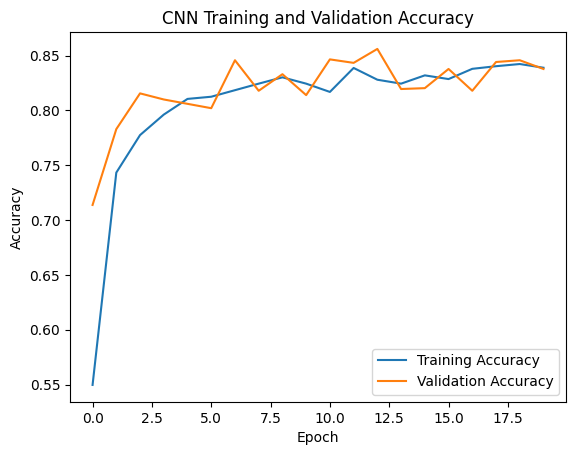

In [29]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.show()

**Observation:** Both training and validation accuracy increase during the initial epochs and then stabilize at approximately 83–85%. The two curves remain relatively close throughout training, indicating that the model learns useful patterns without showing a large difference between training and validation performance.

## Conclusion

This project developed a 1D Convolutional Neural Network (CNN) model to classify transmission line operating conditions using three-phase current and voltage measurements.

The dataset was preprocessed and analysed before the six electrical measurements Ia, Ib, Ic, Va, Vb and Vc were used as input features. The CNN was trained to classify six conditions: No Fault, LG, LL, LLG, LLL and LLLG.

The developed model achieved a test accuracy of approximately 84.17%. It showed strong classification performance for LG, LL, LLG and No Fault conditions. However, the model experienced difficulty distinguishing between LLL and LLLG faults.

Overall, the results demonstrate that a 1D CNN can learn useful patterns from electrical measurements for transmission line fault classification.

### Limitations and Future Improvements

**Limitations:** The model was developed using data obtained from a simulated electrical power system, so its performance on real-world transmission line measurements is not established. The model also showed difficulty distinguishing between LLL and LLLG faults.

**Future Improvements:** The model can be further evaluated using real-world transmission line data and additional operating conditions. Future work may also investigate improvements to the CNN architecture and model parameters to improve the classification of similar fault types such as LLL and LLLG.

## Project Flow Diagram

Problem Definition  
↓  
Dataset Collection  
↓  
Dataset Understanding  
↓  
Data Preprocessing  
↓  
Exploratory Data Analysis  
↓  
Feature Selection  
↓  
Target Label Encoding  
↓  
Train-Test Split  
↓  
Feature Scaling  
↓  
Data Reshaping for 1D CNN  
↓  
1D CNN Model Building  
↓  
Model Training  
↓  
Model Evaluation (Accuracy, Precision, Recall & F1-Score)  
↓  
Confusion Matrix & Interpretation  
↓  
Conclusion